# Analisis Sentimen Ulasan Aplikasi SimSimi pada Google Play Store dengan Python

**Author:** Desnia Anindy Irni Hareva  
**ID:** MC312D5X1494  
**Username:** desniaanindy

### Library

Pada tahap awal, dilakukan instalasi dan import pustaka untuk analisis sentimen ulasan aplikasi SimSimi, yang terbagi dalam beberapa kategori:

1. **Instalasi Eksternal**
   - `Sastrawi`: Digunakan untuk menghapus kata-kata tidak penting dalam bahasa Indonesia.

2. **Manipulasi Data dan Visualisasi**
   - `pandas`, `numpy`: Untuk pengolahan data.
   - `matplotlib.pyplot`, `seaborn`: Untuk membuat grafik.
   - `WordCloud`: Untuk menampilkan kata-kata yang sering muncul.

3. **Pemrosesan Teks**
   - `re`, `string`, `json`, `requests`, `pickle`: Utilitas untuk pemrosesan teks.
   - `nltk`: Untuk tokenisasi dan pengelolaan stopwords dalam bahasa Inggris.
   - `Sastrawi.StopWordRemoverFactory`: Untuk menghapus stopwords dalam bahasa Indonesia.
   - Beberapa dependensi NLTK seperti `punkt` juga diunduh.

4. **Pembelajaran Mesin**
   - `TfidfVectorizer`: Mengonversi teks menjadi data numerik.
   - `train_test_split`: Untuk membagi dataset.
   - `SVC`, `RandomForestClassifier`: Model-model klasifikasi.
   - `accuracy_score`, `precision_score`, `classification_report`, `confusion_matrix`: Untuk menganalisis performa model.

5. **Pembelajaran Mendalam**
   - `Tokenizer`, `pad_sequences`, `Sequential`, dan layer Keras untuk membangun model LSTM atau GRU.
   - `EarlyStopping`, `ReduceLROnPlateau`: Untuk meningkatkan efisiensi pelatihan.
   - `Adam`, `l2`: Sebagai optimizer dan regularizer.

6. **Lain-lain**
   - `warnings`: Untuk menyembunyikan pesan peringatan saat notebook dijalankan.

In [ ]:
# Instalasi pustaka yang dibutuhkan
!pip install Sastrawi

# Pustaka untuk manipulasi data dan visualisasi
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Pemrosesan teks
import re
import string
import json
import requests
import pickle
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk import download as nltk_unduh
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# Mengunduh dependensi NLTK
nltk_unduh('punkt')
nltk_unduh('punkt_tab')
nltk_unduh('stopwords')

# Pustaka untuk pembelajaran mesin
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, classification_report, confusion_matrix

# Pustaka untuk pembelajaran mendalam
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Flatten, GRU, SpatialDropout1D
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, Callback, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

# Menonaktifkan peringatan sistem
import warnings
warnings.filterwarnings("ignore")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 6.9 MB/s eta 0:00:00


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


### Memanggil Dataset

Dataset terdiri dari:
- content: memuat isi ulasan dari para pengguna.
- score: merepresentasikan skor penilaian aplikasi (berkisar dari 1 hingga 5).

In [ ]:
# Read CSV
data = pd.read_csv('dataset (2).csv')
print(data.head())

                content  score
0                  bgus      5
1     rada rada sih emg      5
2             agak agak      5
3  sering berkata suara      1
4                bagus👍      5


### Exploratory Data Analysis (EDA)



**Cek Missing Value**

In [ ]:
data.info()

# Mengecek jumlah data yang kosong di setiap kolom
print("Jumlah data kosong per kolom:")
print(data.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  20000 non-null  object
 1   score    20000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 312.6+ KB
Jumlah data kosong per kolom:
content    0
score      0
dtype: int64


Pada tahap ini, dilakukan pengecekan terhadap struktur dan kelengkapan dataset untuk mendeteksi masalah seperti data yang hilang

**Distribusi Rating**

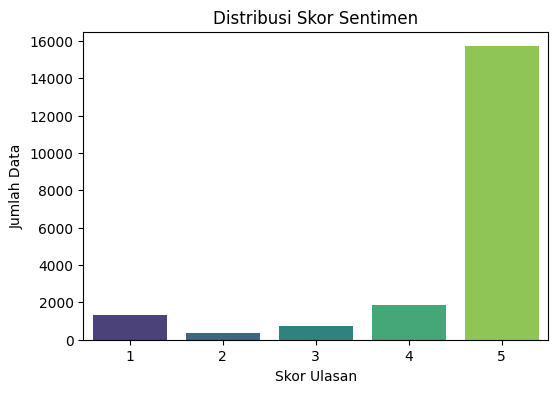

score
5    15700
4     1848
1     1325
3      758
2      369
Name: count, dtype: int64


In [ ]:
# Membuat visualisasi distribusi skor ulasan aplikasi SimSimi
plt.figure(figsize=(6, 4))
sns.countplot(x=data['score'], palette='viridis')
plt.title("Distribusi Skor Sentimen")
plt.xlabel("Skor Ulasan")
plt.ylabel("Jumlah Data")
plt.show()

# Menampilkan jumlah ulasan untuk setiap nilai skor
print(data['score'].value_counts())

### Text Preprocessing




In [ ]:
# Membersihkan teks ulasan
def proses_teks(teks):
    teks = re.sub(r'@[A-Za-z0-9_]+', '', teks)        # Menghapus mention
    teks = re.sub(r'#[A-Za-z0-9_]+', '', teks)        # Menghapus hashtag
    teks = re.sub(r'[²]', ' ', teks)                  # Menghapus karakter aneh
    teks = re.sub(r'\d+', ' ', teks)                  # Menghapus angka
    teks = re.sub(r'[^\w\s]', ' ', teks)              # Menghapus tanda baca
    teks = teks.strip()                               # Menghapus spasi berlebih
    teks = teks.lower()                               # Konversi ke huruf kecil semua
    return teks

**Tokenisasi Teks**
Memecah setiap ulasan yang sudah dibersihkan menjadi potongan kata-kata (token) supaya komputer bisa memprosesnya.

In [ ]:
# Tokenisasi teks ulasan
def tokenisasi_teks(teks):
    return word_tokenize(teks)

**Menjalankan Stopwords** untuk membuang kata-kata umum yang tidak penting.

In [38]:
# Filter stopwords dari token
def filter_stopwords(teks):
    daftar_stopwords = set(stopwords.words('indonesian')).union(stopwords.words('english'))

    # Menambahkan kata-kata informal ke stopwords
    tambahan_stopword = [
        'iya', 'yaa', 'gak', 'nya', 'na', 'sih', 'ku',
        'di', 'ga', 'ya', 'gaa', 'loh', 'kah', 'woi', 'woii', 'woy'
    ]
    daftar_stopwords.update(tambahan_stopword)

    return [kata for kata in teks if kata not in daftar_stopwords]

(Tambahan) **Mengganti Kata Gaul**

In [39]:
# Load kata slang dari URL
def muat_kata_slang(url):
    resp = requests.get(url)
    if resp.status_code == 200:
        return resp.json()
    else:
        print(f"Error mengambil slang dari {url}")
        return {}

# URL file slangwords
url = "https://raw.githubusercontent.com/azzhrdania/Proyek-Analisis-Sentimen-Gojek/refs/heads/main/Datasets/slangwords.json"

# Memuat kamus slang
kata_slang = muat_kata_slang(url)

# Ganti slang jadi kata baku
def perbaiki_kata_slang(teks):
    kata_list = teks.split()
    kata_diperbaiki = [kata_slang.get(kata.lower(), kata) for kata in kata_list]
    return ' '.join(kata_diperbaiki)

In [40]:
# Gabung token jadi kalimat
def gabungkan_ke_kalimat(tokens):
    return ' '.join(tokens)

data['clean_text'] = data['content'].apply(proses_teks)
data['text_slangwords'] = data['clean_text'].apply(perbaiki_kata_slang)
data['text_tokenizing'] = data['text_slangwords'].apply(tokenisasi_teks)
data['text_stopword'] = data['text_tokenizing'].apply(filter_stopwords)
data['clean_content'] = data['text_stopword'].apply(gabungkan_ke_kalimat)

**Leksikon**

In [41]:
# Fungsi untuk memuat kata positif/negatif
def ambil_lexikon(url):
    resp = requests.get(url)
    if resp.status_code == 200:
        return set(kata.strip() for kata in resp.text.splitlines() if kata.strip())
    else:
        print(f"Gagal mengambil lexikon dari {url} (status: {resp.status_code})")
        return set()

# URL untuk lexikon positif dan negatif
url_positif = "https://raw.githubusercontent.com/masdevid/ID-OpinionWords/master/positive.txt"
url_negatif = "https://raw.githubusercontent.com/masdevid/ID-OpinionWords/master/negative.txt"

lexikon_positif = ambil_lexikon(url_positif)
lexikon_negatif = ambil_lexikon(url_negatif)

print(f"Jumlah kata positif: {len(lexikon_positif)}")
print(f"Jumlah kata negatif: {len(lexikon_negatif)}")

Jumlah kata positif: 1182
Jumlah kata negatif: 2402


**Menentukan Sentimen**

In [42]:
# Fungsi untuk menentukan label sentimen
def tentukan_sentimen(teks):
    skor = 0
    for kata in teks:
        if kata in lexikon_positif:
            skor += 1
        if kata in lexikon_negatif:
            skor -= 1

    if skor > 0:
        return skor, 'positif'
    elif skor < 0:
        return skor, 'negatif'
    else:
        return skor, 'netral'

# Menerapkan fungsi ke dataset
hasil_sentimen = data['text_stopword'].apply(tentukan_sentimen)
skor_sentimen, label_sentimen = zip(*hasil_sentimen)
data['sentimen_skor'] = skor_sentimen
data['sentimen'] = label_sentimen

**Visualisasi Distribusi Sentimen**

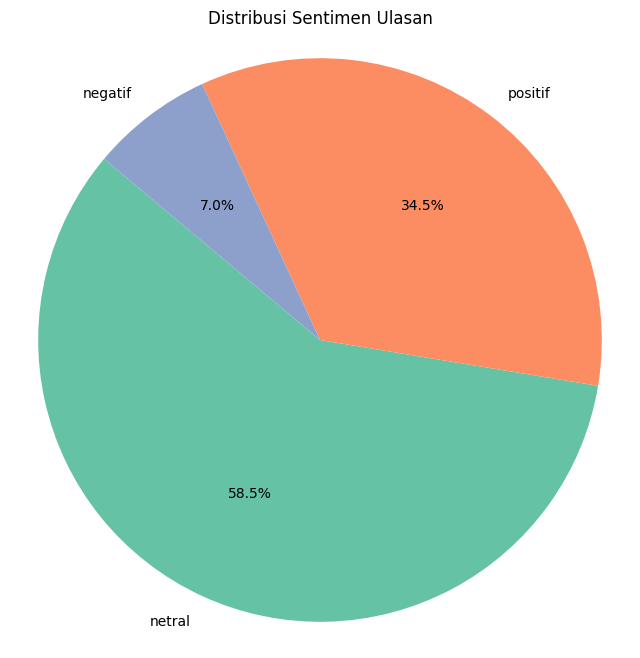

In [43]:
jumlah_sentimen = data['sentimen'].value_counts()

# Pie chart distribusi sentimen
plt.figure(figsize=(8, 8))
plt.pie(
    jumlah_sentimen,
    labels=jumlah_sentimen.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('Set2')
)
plt.title('Distribusi Sentimen Ulasan')
plt.axis('equal')  # Membuat pie menjadi bulat
plt.show()

### Data Preparation

In [44]:
# Ambil kolom 'clean_content' sebagai fitur (X) dan 'sentimen' sebagai label (y)
fitur = data['clean_content'].astype(str)
label = data['sentimen'].replace({'positif': 2, 'netral': 1, 'negatif': 0})

# Transformasi teks ke vektor angka menggunakan TF-IDF
TFIDF = TfidfVectorizer(max_features=10000, lowercase=True, ngram_range=(1,1))
fitur_TFIDF = TFIDF.fit_transform(fitur)

# Menampilkan ringkasan dimensi data hasil vektorisasi
print("Ringkasan Fitur dan Data:")
print(f"Dimensi fitur TF-IDF: {fitur_TFIDF.shape[0]} sampel x {fitur_TFIDF.shape[1]} fitur")

Ringkasan Fitur dan Data:
Dimensi fitur TF-IDF: 20000 sampel x 9189 fitur


### LSTM

In [45]:
# Menginisialisasi tokenizer dan membatasi jumlah kata unik sebanyak 10.000
tokenizer = Tokenizer(num_words=10000)

# Menyesuaikan tokenizer dengan teks yang telah dibersihkan
tokenizer.fit_on_texts(fitur)

# Mengubah teks menjadi urutan angka berdasarkan kamus tokenizer
fitur_sekuensial = tokenizer.texts_to_sequences(fitur)

# Menyamakan panjang urutan dengan padding (maksimal 100 kata)
fitur_padat = pad_sequences(fitur_sekuensial, maxlen=100)

In [47]:
# Menghitung jumlah kelas sentimen
jumlah_kelas = np.unique(label).shape[0]
print(f"Jumlah kelas sentimen: {jumlah_kelas}")

# Menampilkan dimensi dari fitur hasil padding
print(f"Dimensi fitur setelah padding: {fitur_padat.shape}")

# Menampilkan ukuran kosa kata dari tokenizer
kosa_kata_index = tokenizer.word_index
print(f"Jumlah total kata pada kamus tokenizer: {len(kosa_kata_index)} kata")

Jumlah kelas sentimen: 3
Dimensi fitur setelah padding: (20000, 100)
Jumlah total kata pada kamus tokenizer: 9231 kata


**Membagi Dataset untuk Training (70%), Testing (20%), Validation (10%)**

In [48]:
# Membagi data menjadi: pelatihan (70%), pengujian (20%), dan validasi (10%)
fitur_latih_lstm, fitur_uji_lstm, label_latih_lstm, label_uji_lstm = train_test_split(
    fitur_padat, label, test_size=0.2, random_state=42
)

# Mengambil 10% dari 80% data latih sebagai data validasi (0.1 / 0.8 = 0.125)
fitur_latih_lstm, fitur_validasi_lstm, label_latih_lstm, label_validasi_lstm = train_test_split(
    fitur_latih_lstm, label_latih_lstm, test_size=0.125, random_state=42
)

# Menampilkan jumlah sampel di setiap subset
print("Total Sampel:")
print(f"Set pelatihan: {fitur_latih_lstm.shape[0]} sampel")
print(f"Set validasi : {fitur_validasi_lstm.shape[0]} sampel")
print(f"Set pengujian: {fitur_uji_lstm.shape[0]} sampel")

Total Sampel:
Set pelatihan: 14000 sampel
Set validasi : 2000 sampel
Set pengujian: 4000 sampel


**Melatih Model LSTM**

In [49]:
# Membuat model LSTM untuk klasifikasi sentimen
model_lstm = Sequential([
    Embedding(input_dim=10000, output_dim=128, input_length=100),       # Representasi kata dalam vektor
    SpatialDropout1D(0.4),                                               # Dropout untuk regularisasi
    LSTM(128, dropout=0.3, recurrent_dropout=0.3),                       # LSTM untuk memahami urutan kata
    Dense(3, activation='softmax')                                       # Output 3 kelas sentimen
])

# Menyusun model dengan loss dan optimizer
model_lstm.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=Adam(),
    metrics=['accuracy']
)

# Callback untuk kontrol pelatihan
callback_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)
callback_lr_reduction = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2
)

# Daftar callback
callbacks = [callback_early_stopping, callback_lr_reduction]

# Menjalankan pelatihan model
riwayat_latihan = model_lstm.fit(
    fitur_latih_lstm, label_latih_lstm,
    validation_data=(fitur_validasi_lstm, label_validasi_lstm),
    epochs=15,
    batch_size=64,
    verbose=1,
    callbacks=callbacks
)

Epoch 1/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 75s 326ms/step - accuracy: 0.6998 - loss: 0.6701 - val_accuracy: 0.8830 - val_loss: 0.2991 - learning_rate: 0.0010
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 81s 322ms/step - accuracy: 0.9260 - loss: 0.2124 - val_accuracy: 0.9515 - val_loss: 0.1415 - learning_rate: 0.0010
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 81s 318ms/step - accuracy: 0.9722 - loss: 0.0828 - val_accuracy: 0.9720 - val_loss: 0.0908 - learning_rate: 0.0010
Epoch 4/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 82s 318ms/step - accuracy: 0.9869 - loss: 0.0401 - val_accuracy: 0.9720 - val_loss: 0.0822 - learning_rate: 0.0010
Epoch 5/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 82s 317ms/step - accuracy: 0.9934 - loss: 0.0214 - val_accuracy: 0.9760 - val_loss: 0.0845 - learning_rate: 0.0010
Epoch 6/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 81s 311ms/step - accuracy: 0.9948 - loss: 0.0179 - val_accuracy: 0.9760 - val_loss: 0.0739 - learning_rate: 0.0010
Epoch 7/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 81s 309ms/step - accuracy: 0.9

**Evaluasi Performa Model LSTM**

In [50]:
# Mengambil nilai akurasi pelatihan terakhir
akurasi_latih = riwayat_latihan.history['accuracy']

# Evaluasi terhadap data pengujian
kerugian_uji, akurasi_lstm = model_lstm.evaluate(fitur_uji_lstm, label_uji_lstm, verbose=0)

# Menampilkan hasil evaluasi
print("\nEvaluasi Model LSTM:")
print(f"Akurasi terakhir pada data pelatihan: {akurasi_latih[-1]:.4f}")
print(f"Akurasi akhir pada data pengujian: {akurasi_lstm:.4f}")

# Prediksi terhadap data uji
y_prediksi = np.argmax(model_lstm.predict(fitur_uji_lstm, verbose=0), axis=1)

# Menampilkan laporan klasifikasi
print("\nLaporan Klasifikasi:")
print(classification_report(label_uji_lstm, y_prediksi, target_names=['negatif', 'netral', 'positif']))


Evaluasi Model LSTM:
Akurasi terakhir pada data pelatihan: 0.9976
Akurasi akhir pada data pengujian: 0.9737

Laporan Klasifikasi:
              precision    recall  f1-score   support

     negatif       0.92      0.90      0.91       283
      netral       0.98      0.98      0.98      2318
     positif       0.98      0.98      0.98      1399

    accuracy                           0.97      4000
   macro avg       0.96      0.95      0.96      4000
weighted avg       0.97      0.97      0.97      4000



**Confusion Matrix Model LSTM**

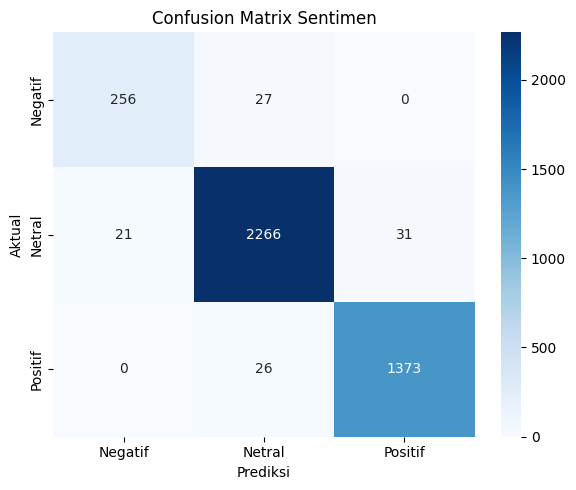

In [51]:
# Membuat confusion matrix
matriks_konfusi = confusion_matrix(label_uji_lstm, y_prediksi)

# Label kelas
label_kategori = ['Negatif', 'Netral', 'Positif']

# Menampilkan confusion matrix menggunakan heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(matriks_konfusi, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_kategori, yticklabels=label_kategori)
plt.title('Confusion Matrix Sentimen')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.show()

### SVM

**Membagi Data Training (80%) dan Testing (20%)**

In [52]:
# Membagi data menjadi set pelatihan dan pengujian
X_latih_svm, X_uji_svm, y_latih_svm, y_uji_svm = train_test_split(fitur_TFIDF, label, test_size=0.2, random_state=42)

# Menampilkan jumlah sampel pada setiap set
print("Jumlah Total Sampel:")
print(f"Set Latih: {X_latih_svm.shape[0]} sampel")
print(f"Set Uji: {X_uji_svm.shape[0]} sampel")

Jumlah Total Sampel:
Set Latih: 16000 sampel
Set Uji: 4000 sampel


**Pelatihan Model SVM**

In [53]:
# Membuat model SVM dengan kernel linear
model_svm = SVC(kernel='linear', probability=True)

# Melatih model terhadap data latih
model_svm.fit(X_latih_svm, y_latih_svm)

# Melakukan prediksi pada data uji
y_pred_svm = model_svm.predict(X_uji_svm)

**Evaluasi Model SVM**


Evaluasi Model SVM + TF-IDF
Akurasi pada Data Latih: 0.9844
Akurasi pada Data Uji: 0.9587

Laporan Klasifikasi:
              precision    recall  f1-score   support

     negatif       0.95      0.75      0.84       283
      netral       0.95      0.98      0.97      2318
     positif       0.98      0.96      0.97      1399

    accuracy                           0.96      4000
   macro avg       0.96      0.90      0.92      4000
weighted avg       0.96      0.96      0.96      4000



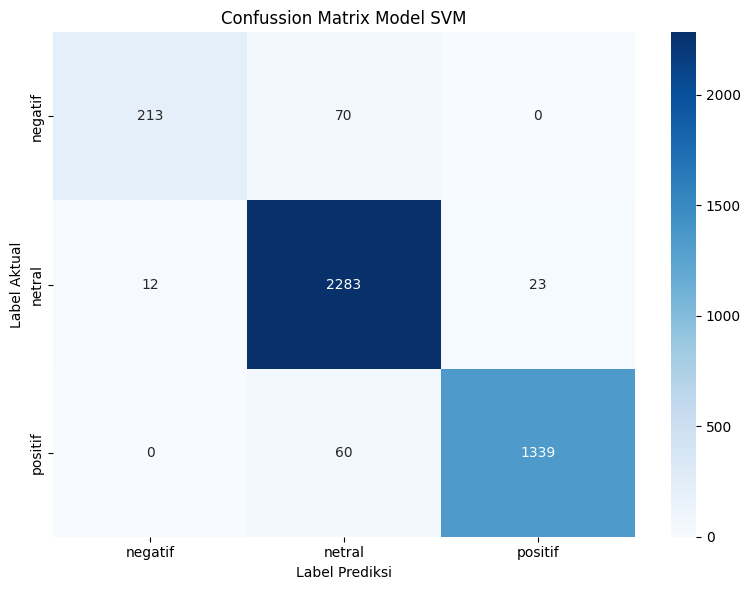

In [54]:
# Menghitung akurasi model
akurasi_latih_svm = accuracy_score(y_latih_svm, model_svm.predict(X_latih_svm))
akurasi_svm = accuracy_score(y_uji_svm, y_pred_svm)

# Menampilkan hasil evaluasi
print("\nEvaluasi Model SVM + TF-IDF")
print(f"Akurasi pada Data Latih: {akurasi_latih_svm:.4f}")
print(f"Akurasi pada Data Uji: {akurasi_svm:.4f}")

# Menampilkan laporan klasifikasi
print("\nLaporan Klasifikasi:")
print(classification_report(y_uji_svm, y_pred_svm, target_names=['negatif', 'netral', 'positif']))

# Visualisasi confussion matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_uji_svm, y_pred_svm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['negatif', 'netral', 'positif'],
            yticklabels=['negatif', 'netral', 'positif'])
plt.title('Confussion Matrix Model SVM')
plt.xlabel('Label Prediksi')
plt.ylabel('Label Aktual')
plt.tight_layout()
plt.show()

### Random Forest

**Membagi Data Training (70%) dan Testing (30%)**

In [55]:
# Membagi data menjadi set latih dan uji (70% latih, 30% uji)
X_latih_rf, X_uji_rf, y_latih_rf, y_uji_rf = train_test_split(fitur_TFIDF, label, test_size=0.3, random_state=42)

# Menampilkan jumlah sampel
print("Distribusi Sampel:")
print(f"Set Latih: {X_latih_rf.shape[0]} sampel")
print(f"Set Uji: {X_uji_rf.shape[0]} sampel")

Distribusi Sampel:
Set Latih: 14000 sampel
Set Uji: 6000 sampel


**Pelatihan Model Random Forest**

In [56]:
# Inisialisasi model Random Forest dengan hyperparameter yang disesuaikan
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

# Melatih model menggunakan data latih
rf_model.fit(X_latih_rf, y_latih_rf)

# Melakukan prediksi pada data uji
y_pred_rf = rf_model.predict(X_uji_rf)

**Evaluasi Model Random Forest**


Evaluasi Model Random Forest + TF-IDF
Akurasi pada Data Latih: 0.9454
Akurasi pada Data Uji: 0.9253

Laporan Klasifikasi:
              precision    recall  f1-score   support

     negatif       0.92      0.56      0.69       427
      netral       0.92      0.95      0.94      3488
     positif       0.93      0.95      0.94      2085

    accuracy                           0.93      6000
   macro avg       0.92      0.82      0.86      6000
weighted avg       0.93      0.93      0.92      6000



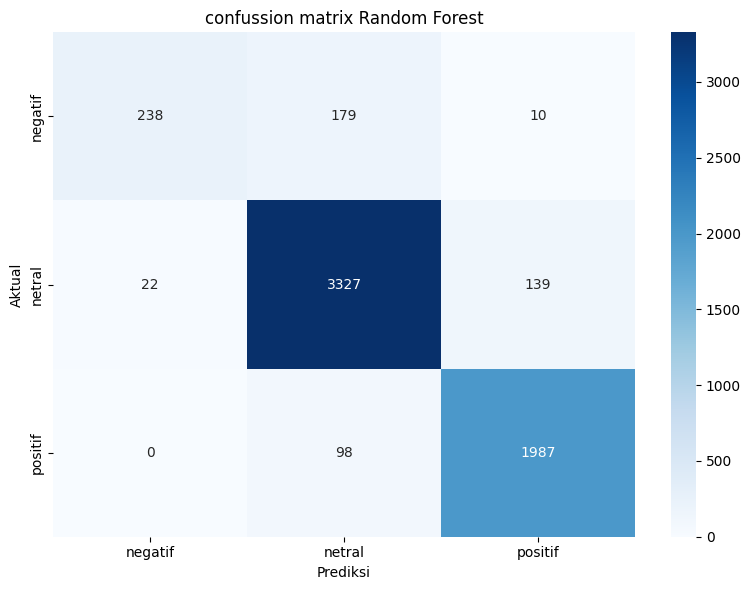

In [57]:
# Mengukur akurasi model
akurat_latih = accuracy_score(y_latih_rf, rf_model.predict(X_latih_rf))
akurat_uji_rf = accuracy_score(y_uji_rf, y_pred_rf)

# Menampilkan hasil evaluasi
print("\nEvaluasi Model Random Forest + TF-IDF")
print(f"Akurasi pada Data Latih: {akurat_latih:.4f}")
print(f"Akurasi pada Data Uji: {akurat_uji_rf:.4f}")

# Menampilkan laporan klasifikasi
print("\nLaporan Klasifikasi:")
print(classification_report(y_uji_rf, y_pred_rf, target_names=['negatif', 'netral', 'positif']))

# Visualisasi confussion matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_uji_rf, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['negatif', 'netral', 'positif'],
            yticklabels=['negatif', 'netral', 'positif'])
plt.title('confussion matrix Random Forest')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.show()

### Perbandingan Performa Model

In [58]:
# Membuat tabel ringkasan performa model
ringkasan = {
    'Model': ['LSTM', 'SVM', 'Random Forest'],
    'Akurasi': [akurasi_lstm, akurasi_svm, akurat_uji_rf],  # gunakan nama variabel yang benar
    'Rasio Pembagian Data': ['80/20', '80/20', '70/30'],
    'Jenis Fitur': ['Word Embedding', 'TF-Idata', 'TF-Idata']
}

# Mengonversi ke DataFrame
data_ringkasan = pd.DataFrame(ringkasan)

# Format akurasi menjadi persen
data_ringkasan['Akurasi'] = data_ringkasan['Akurasi'].apply(lambda x: f"{x:.2%}")

# Menampilkan ringkasan
print("Ringkasan Hasil Evaluasi Model")
display(data_ringkasan)

Ringkasan Hasil Evaluasi Model


,Model,Akurasi,Rasio Pembagian Data,Jenis Fitur
0,LSTM,97.37%,80/20,Word Embedding
1,SVM,95.88%,80/20,TF-Idata
2,Random Forest,92.53%,70/30,TF-Idata


Langkah ini dilakukan untuk menyimpan model hasil pelatihan beserta komponen pendukung seperti TF-Idata vectorizer dan tokenizer agar dapat digunakan kembali tanpa perlu melatih ulang.

In [68]:
model_lstm.save("../Models/lstm_sentiment_model.h5")
with open("../Models/svm_sentiment_model.pkl", "wb") as f:
    pickle.dump(model_svm, f)
with open("../Models/rf_sentiment_model.pkl", "wb") as f:
    pickle.dump(rf_model, f)
with open("../Models/vectorizer.pkl", "wb") as f:
    pickle.dump(TFIDF, f)
with open("../Models/tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

In [71]:
# Memuat model LSTM dari file .h5 yang berada di dalam folder ../Models
lstm_model = tf.keras.models.load_model("../Models/lstm_sentiment_model.h5")

# Membuka dan memuat model SVM dari file pickle
with open("../Models/svm_sentiment_model.pkl", "rb") as f:
    svm_model = pickle.load(f)

# Membuka dan memuat model Random Forest dari file pickle
with open("../Models/rf_sentiment_model.pkl", "rb") as f:
    rf_model = pickle.load(f)

# Memuat kembali TF-IDF Vectorizer untuk mentransformasi teks ke bentuk vektor numerik
with open("../Models/vectorizer.pkl", "rb") as f:
    vectorizer = pickle.load(f)

# Memuat tokenizer untuk mengubah teks menjadi urutan token angka untuk model LSTM
with open("../Models/tokenizer.pkl", "rb") as f:
    tokenizer = pickle.load(f)

### Model Deployment: Inference Function

In [72]:
# Mapping label numerik ke label string agar hasil prediksi lebih mudah dibaca
label_map = {0: "negative", 1: "neutral", 2: "positive"}

# Data teks baru
new_texts = [
    "Aplikasi ini sangat menghibur dan responsnya menyenangkan.",
    "Jawaban dari aplikasi ini sering tidak relevan dan membuat frustrasi.",
    "Beberapa jawaban cukup baik, namun banyak juga yang biasa saja."
]

# Melakukan preprocessing untuk LSTM
new_sequences = tokenizer.texts_to_sequences(new_texts)
new_padded = pad_sequences(new_sequences, maxlen=100)

# Melakukan preprocessing untuk SVM dan Random Forest
new_tfidf = TFIDF.transform(new_texts)

# Prediksi
lstm_preds = np.argmax(lstm_model.predict(new_padded), axis=1)
svm_preds = svm_model.predict(new_tfidf)
rf_preds = rf_model.predict(new_tfidf)

# Confidence (opsional, kalau mau dihitung juga probabilitasnya)
lstm_conf = np.max(lstm_model.predict(new_padded), axis=1)
svm_conf = np.max(svm_model.predict_proba(new_tfidf), axis=1)
rf_conf = np.max(rf_model.predict_proba(new_tfidf), axis=1)

# Membuat hasil ke dalam bentuk DataFrame
hasil_prediksi = []
print("\n=== Sentiment Prediction Results ===")
for i, text in enumerate(new_texts):
    hasil_prediksi.append({
        'Text': text,
        'LSTM Prediction': label_map[lstm_preds[i]],
        'LSTM Confidence': f"{lstm_conf[i]:.4f}",
        'SVM Prediction': label_map[svm_preds[i]],
        'SVM Confidence': f"{svm_conf[i]:.4f}",
        'Random Forest Prediction': label_map[rf_preds[i]],
        'Random Forest Confidence': f"{rf_conf[i]:.4f}"
    })

# Tampilkan tabel
display(pd.DataFrame(hasil_prediksi))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step

=== Sentiment Prediction Results ===


,Text,LSTM Prediction,LSTM Confidence,SVM Prediction,SVM Confidence,Random Forest Prediction,Random Forest Confidence
0,Aplikasi ini sangat menghibur dan responsnya m...,positive,0.9984,positive,1.0000,positive,0.7345
1,Jawaban dari aplikasi ini sering tidak relevan...,neutral,0.9763,neutral,0.9690,neutral,0.4880
2,"Beberapa jawaban cukup baik, namun banyak juga...",neutral,1.0000,neutral,0.9739,neutral,0.9576


### Improve

- Perluas kosakata sentimen dengan menambahkan lebih banyak kata dalam Bahasa Indonesia.
- Tambahkan penanganan terhadap kalimat negatif (misalnya, 'tidak bagus' dikategorikan sebagai sentimen negatif).
- Gunakan embedding pra-latih seperti FastText untuk menghasilkan representasi fitur yang lebih baik.
- Terapkan teknik cross-validation untuk mendapatkan evaluasi model yang lebih kuat dan akurat.

